In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path().resolve().parents[0]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
    
    

from src.config import PROCESSED_DATA_DIR
from src.utils.plots import save_figure, style_plot, create_figure, add_bar_labels, add_source, YOUTUBE_RED, save_table, interpret_eta_squared, DARK_RED
import pandas as pd

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/duration-group-distribution.png


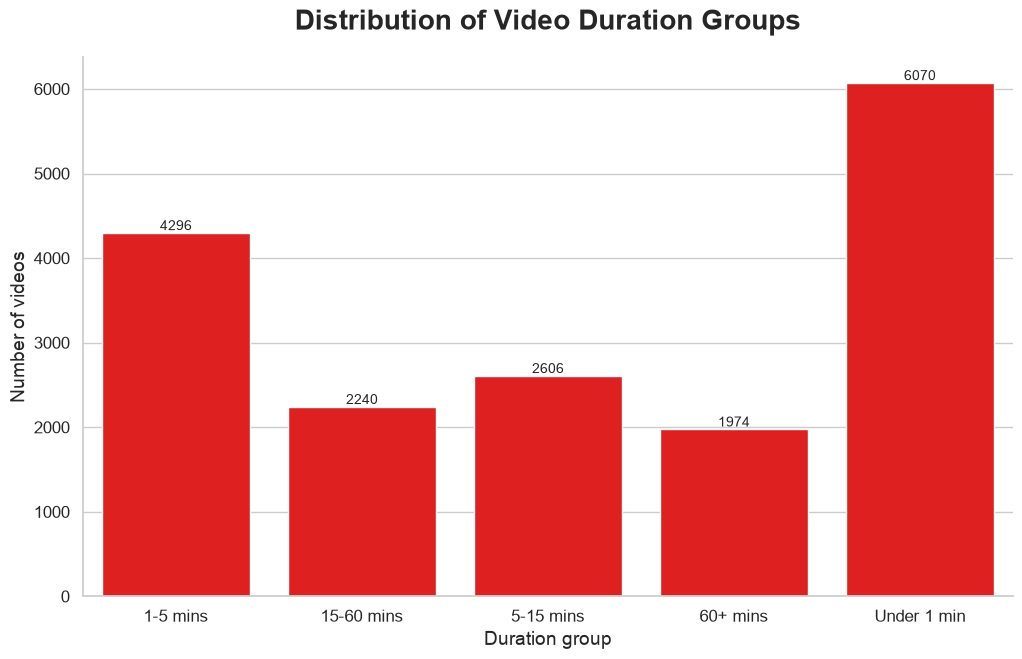

duration_group
Under 1 min    6070
1-5 mins       4296
5-15 mins      2606
15-60 mins     2240
60+ mins       1974
Name: count, dtype: int64


<Figure size 640x480 with 0 Axes>

In [5]:
df = pd.read_csv(PROCESSED_DATA_DIR / "youtube_clean.csv")

fig, ax = create_figure()

sns.countplot(
    data=df,
    x="duration_group",
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Duration group",
    ylabel="Number of videos",
    title="Distribution of Video Duration Groups"
)

add_bar_labels(ax)

save_figure(
    fig=fig,
    filename="q3/duration-group-distribution.png"
)

plt.show()
plt.clf()

print(df["duration_group"].value_counts())

findfont: Failed to find font weight semibold, now using 700.


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/duration-group-visibility.png


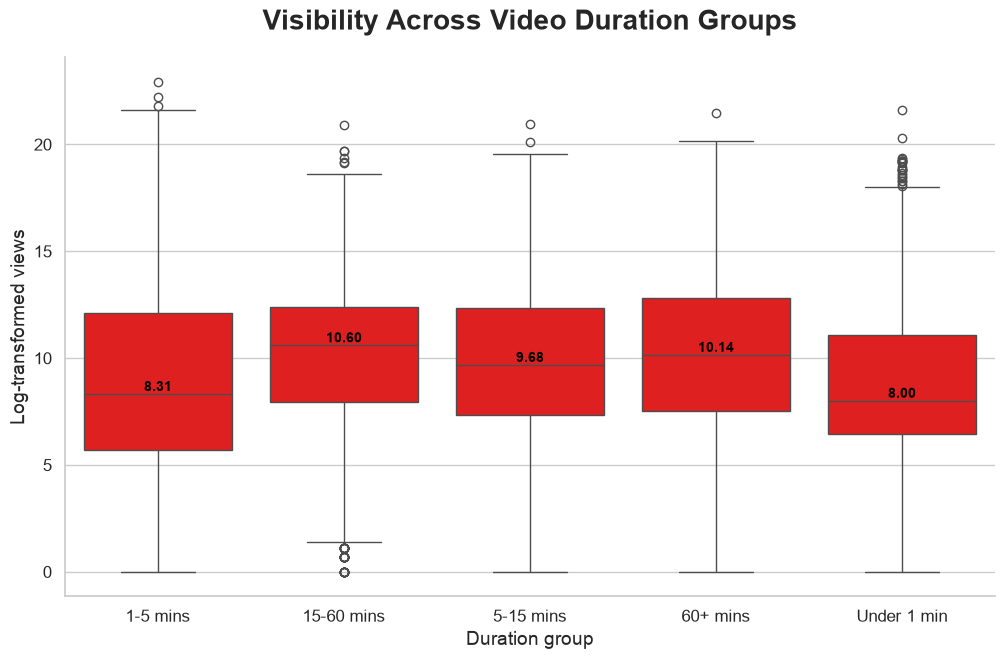

In [6]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="duration_group",
    y="log_views",
    color=YOUTUBE_RED,
    ax=ax
)

# Overlay numeric median labels above each box
medians = df.groupby("duration_group")["log_views"].median()
for i, median in enumerate(medians):
    ax.text(
        x=i, 
        y=median + 0.15,  # Slightly above the median line
        s=f"{median:.2f}", 
        horizontalalignment="center", 
        size=10, 
        color="black", 
        weight="semibold"
    )

style_plot(
    ax=ax,
    xlabel="Duration group",
    ylabel="Log-transformed views",
    title="Visibility Across Video Duration Groups"
)

save_figure(
    fig=fig,
    filename="q3/duration-group-visibility.png"
)

plt.show()
plt.close(fig)

In [ ]:
stats = df.groupby("duration_group")["log_views"].describe()
print(stats[["count", "50%", "25%", "75%", "min", "max"]])

                 count        50%       25%        75%  min        max
duration_group                                                        
1-5 mins        4296.0   8.312855  5.722767  12.114163  0.0  22.929917
15-60 mins      2240.0  10.595083  7.928578  12.415794  0.0  20.919266
5-15 mins       2606.0   9.677082  7.337750  12.356565  0.0  20.967105
60+ mins        1974.0  10.144202  7.540611  12.809521  0.0  21.487002
Under 1 min     6070.0   8.000014  6.446116  11.069384  0.0  21.615661


In [10]:
# test if video duration significantly influence views
from scipy.stats import kruskal

groups = [
    group["log_views"].dropna()
    for _, group in df.groupby("duration_group")
]

statistic, p_value = kruskal(*groups)

print(f"Kruskal-Wallis H statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6f}")

print('----------------')
# epsilon-squared.
n = len(df)
k = df["duration_group"].nunique()

epsilon_squared = (
    statistic - k + 1
) / (n - k)

print(f"Epsilon-squared: {epsilon_squared:.4f}")

Kruskal-Wallis H statistic: 498.4275
p-value: 0.000000
----------------
Epsilon-squared: 0.0287


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/category-visibility.png


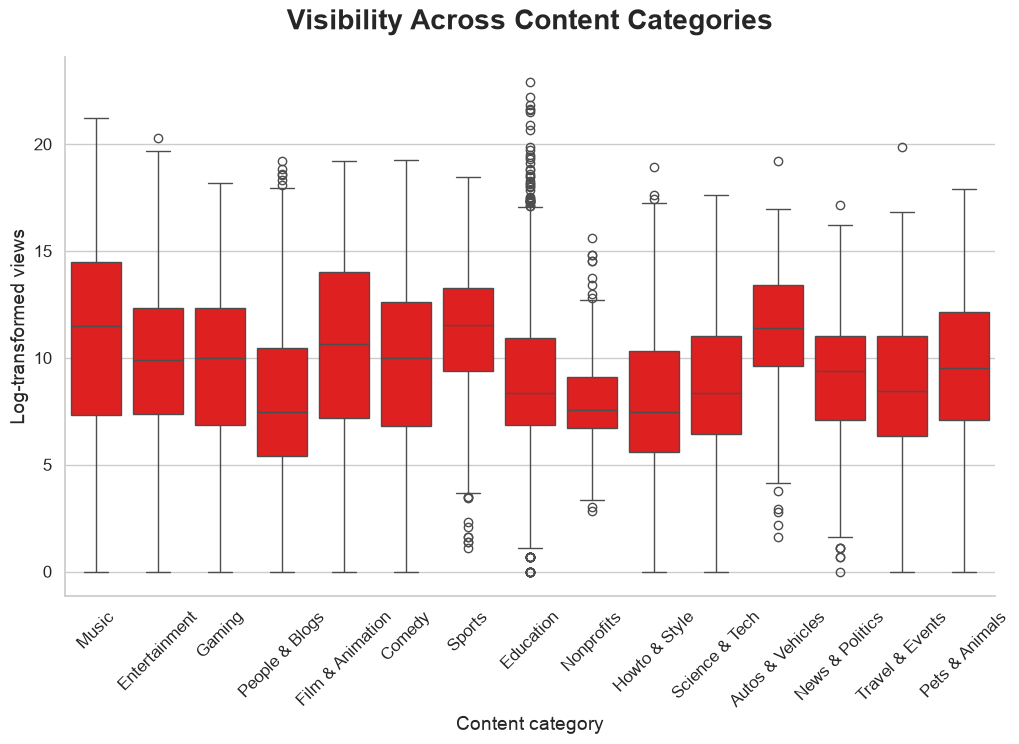

<Figure size 640x480 with 0 Axes>

In [16]:
# content categoried

fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="category_name",
    y="log_views",
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Content category",
    ylabel="Log-transformed views",
    title="Visibility Across Content Categories"
)

ax.tick_params(axis="x", rotation=45)

save_figure(
    fig=fig,
    filename="q3/category-visibility.png"
)

plt.show()
plt.clf()

In [15]:
stats = df.groupby("category_name")["log_views"].describe()
print(stats[["count", "50%", "25%", "75%", "min", "max"]])

                   count        50%       25%        75%       min        max
category_name                                                                
Autos & Vehicles   233.0  11.398704  9.624897  13.427830  1.609438  19.211475
Comedy             244.0   9.972123  6.833411  12.621326  0.000000  19.249683
Education         1185.0   8.360539  6.843750  10.933875  0.000000  22.929917
Entertainment     3269.0   9.907878  7.380256  12.333494  0.000000  20.306457
Film & Animation   741.0  10.656765  7.190676  14.014002  0.000000  19.229570
Gaming             999.0   9.986725  6.862757  12.355227  0.000000  18.207168
Howto & Style      216.0   7.450628  5.595162  10.317791  0.000000  18.946946
Music             1949.0  11.504440  7.317212  14.500411  0.000000  21.232226
News & Politics    482.0   9.401440  7.079415  11.044057  0.000000  17.150723
Nonprofits          86.0   7.574106  6.696096   9.109862  2.833213  15.588788
People & Blogs    6117.0   7.453562  5.416100  10.443862  0.0000

publication_hour
0      436
1      465
2      360
3      373
4      453
5      530
6      522
7      644
8      590
9      659
10     859
11     998
12     961
13    1005
14    1064
15    1062
16    1084
17    1103
18     873
19     800
20     724
21     664
22     512
23     508
Name: count, dtype: int64
Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/publication-hour-distribution.png


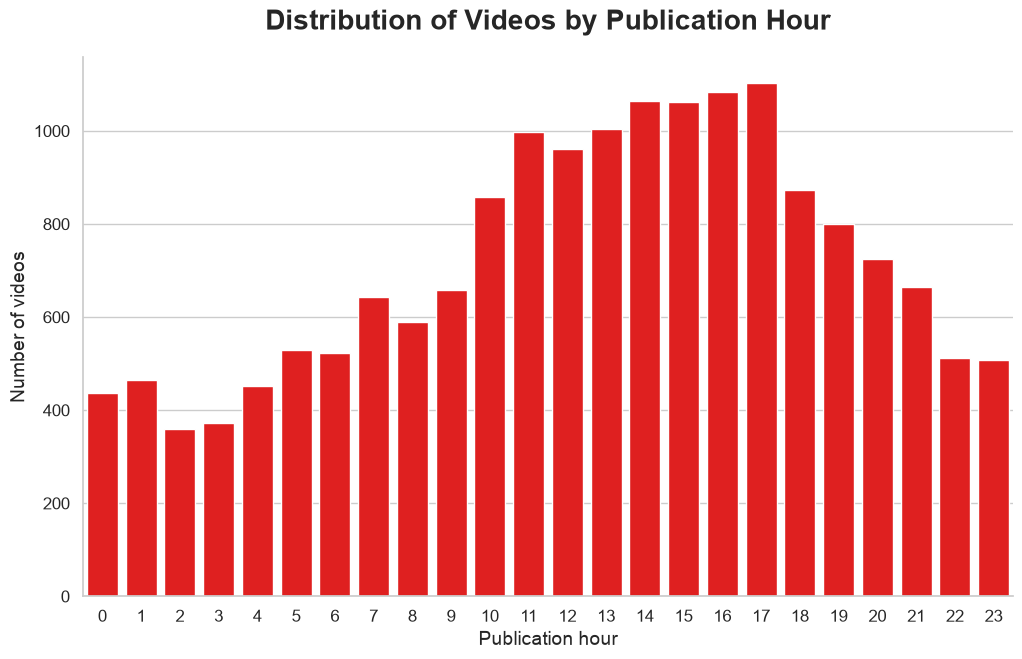

<Figure size 640x480 with 0 Axes>

In [19]:
# views and publication time
df["published_at"] = pd.to_datetime(df["published_at"])

df["publication_hour"] = df["published_at"].dt.hour

print(df["publication_hour"].value_counts().sort_index())


fig, ax = create_figure()

hour_counts = (
    df["publication_hour"]
    .value_counts()
    .sort_index()
)

sns.barplot(
    x=hour_counts.index,
    y=hour_counts.values,
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Publication hour",
    ylabel="Number of videos",
    title="Distribution of Videos by Publication Hour"
)

save_figure(
    fig=fig,
    filename="q3/publication-hour-distribution.png"
)

plt.show()
plt.clf()

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/publication-hour-visibility.png


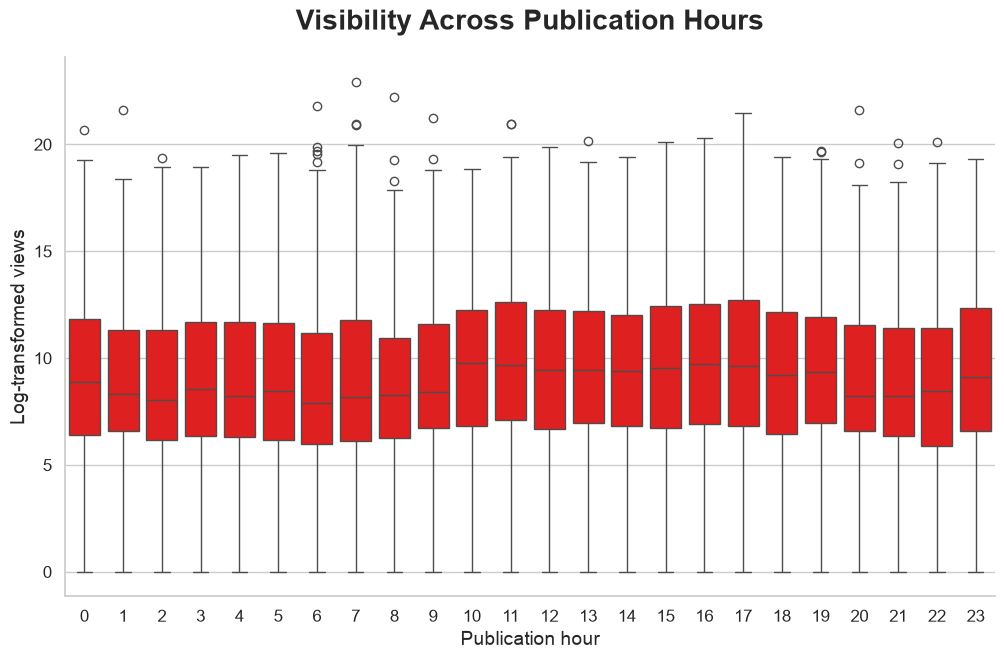

                   count        50%       25%        75%       min        max
category_name                                                                
Autos & Vehicles   233.0  11.398704  9.624897  13.427830  1.609438  19.211475
Comedy             244.0   9.972123  6.833411  12.621326  0.000000  19.249683
Education         1185.0   8.360539  6.843750  10.933875  0.000000  22.929917
Entertainment     3269.0   9.907878  7.380256  12.333494  0.000000  20.306457
Film & Animation   741.0  10.656765  7.190676  14.014002  0.000000  19.229570
Gaming             999.0   9.986725  6.862757  12.355227  0.000000  18.207168
Howto & Style      216.0   7.450628  5.595162  10.317791  0.000000  18.946946
Music             1949.0  11.504440  7.317212  14.500411  0.000000  21.232226
News & Politics    482.0   9.401440  7.079415  11.044057  0.000000  17.150723
Nonprofits          86.0   7.574106  6.696096   9.109862  2.833213  15.588788
People & Blogs    6117.0   7.453562  5.416100  10.443862  0.0000

<Figure size 640x480 with 0 Axes>

In [21]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="publication_hour",
    y="log_views",
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Publication hour",
    ylabel="Log-transformed views",
    title="Visibility Across Publication Hours"
)

save_figure(
    fig=fig,
    filename="q3/publication-hour-visibility.png"
)

plt.show()
plt.clf()

stats = df.groupby("category_name")["log_views"].describe()
print(stats[["count", "50%", "25%", "75%", "min", "max"]])

In [ ]:
def classify_publication_period(hour):
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"


df["publication_period"] = df["publication_hour"].apply(
    classify_publication_period
)

print(df["publication_period"].value_counts())

publication_period_stats = (
    df.groupby("publication_period")["log_views"]
    .describe()
)

print(publication_period_stats)

publication_period
Afternoon    6279
Morning      4272
Evening      4081
Night        2617
Name: count, dtype: int64
